# 08 · Configuración, TFT, herramientas y ejercicios

[Índice](00_indice_y_recorrido.ipynb) · [Anterior](07_pantalla_st7789.ipynb)

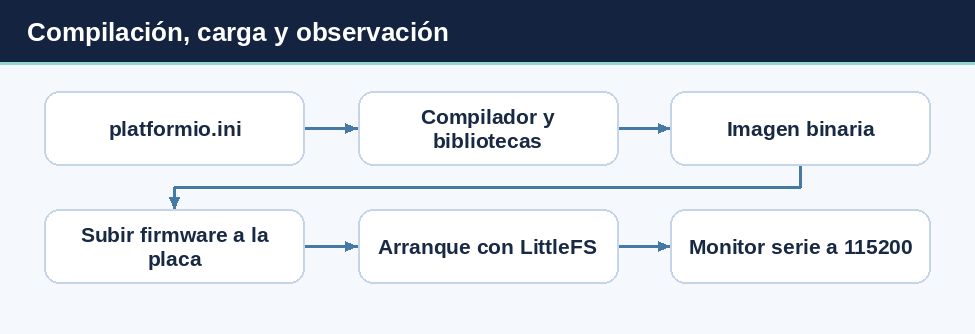

## `platformio.ini`

Cada sección `[env:...]` define un entorno. `platform=espressif32` selecciona la plataforma;
`board=esp32-s3-devkitc-1` selecciona la placa; `framework=arduino` prepara el ciclo setup/loop.
`board_build.filesystem=littlefs` elige el formato de imagen de archivos. `monitor_speed=115200`
debe coincidir con Serial.begin para interpretar la salida serie.

`lib_deps` declara TFT_eSPI, ArduinoJson, PubSubClient y DHT. `^` admite actualizaciones compatibles
según las reglas de versiones de PlatformIO, no fija exactamente cada compilación al número escrito.
Dependencias del framework y transitivas pueden aparecer además en `.pio/libdeps` o paquetes.

### Flags del compilador

- `-D USE_HSPI_PORT`: selecciona HSPI en el firmware principal. La frecuencia de escritura es 20 MHz, definida en TFT_Setup.h. La variante display-test-fspi conserva FSPI a 5 MHz solo para diagnostico.
  Los nombres concretos de periféricos dependen de la implementación para ESP32-S3; no cambia por
  sí sola los GPIO explícitos. No implica que exista una pantalla HSPI diferente.
- `-D USER_SETUP_LOADED`: indica a TFT_eSPI que ya existe configuración propia y evita cargar
  otra configuración predeterminada.
- `-include include/TFT_Setup.h`: fuerza la inclusión del archivo antes de compilar cada unidad
  afectada por estos flags; así la biblioteca recibe los mismos pines que el sketch.

El archivo propio en include se conserva aunque se regeneren las dependencias de .pio.

```ini
; PlatformIO Project Configuration File
;
;   Build options: build flags, source filter
;   Upload options: custom upload port, speed and extra flags
;   Library options: dependencies, extra library storages
;   Advanced options: extra scripting
;
; Please visit documentation for the other options and examples
; https://docs.platformio.org/page/projectconf.html

[platformio]
default_envs = esp32-s3-devkitc-1

[env:esp32-s3-devkitc-1]
platform = espressif32
board = esp32-s3-devkitc-1
framework = arduino
board_build.filesystem = littlefs
monitor_speed = 115200
build_src_filter = +<main.cpp>
build_flags = 
	-D USE_HSPI_PORT
	-D USER_SETUP_LOADED
	-include include/TFT_Setup.h
lib_deps = 
	bodmer/TFT_eSPI@^2.5.43
	bblanchon/ArduinoJson@^7.2.2
	knolleary/PubSubClient@^2.8
	adafruit/DHT sensor library@^1.4.6

; Diagnostico aislado de pantalla, con los mismos pines y bus SPI.
[env:display-test]
extends = env:esp32-s3-devkitc-1
build_src_filter = +<display_test.cpp>

; Variante de diagnostico: bus FSPI explicito y reloj reducido a 5 MHz.
[env:display-test-fspi]
extends = env:display-test
build_flags =
    -D USE_FSPI_PORT
    -D USER_SETUP_LOADED
    -D SPI_FREQUENCY=5000000
    -include include/TFT_Setup.h

```

## `include/TFT_Setup.h`: macros activas

Los comentarios muestran muchas placas/controladores alternativos; las líneas con `//` no tienen
efecto. No hay que activar simultáneamente todos los ejemplos. El código del proyecto no mantiene
implementaciones para esas alternativas: son opciones de la biblioteca.

| Macro activa | Valor / efecto |
|---|---|
| USER_SETUP_INFO | `"User_Setup"`, etiqueta de diagnóstico. |
| ST7789_DRIVER | Selecciona controlador ST7789. |
| TFT_MISO | −1: sin entrada de lectura TFT. |
| TFT_MOSI | GPIO13: datos enviados a pantalla. |
| TFT_SCLK | GPIO12: reloj SPI. |
| TFT_CS | GPIO10: selección del dispositivo. |
| TFT_DC | GPIO9: distingue comando y dato. |
| TFT_RST | GPIO8: reset controlado. |
| LOAD_GLCD | Fuente original pequeña disponible. |
| LOAD_FONT2 | Fuente de 16 píxeles. |
| LOAD_FONT4 | Fuente de 26 píxeles. |
| LOAD_FONT6 | Fuente de 48 píxeles con caracteres numéricos y subconjunto indicado por la biblioteca. |
| LOAD_FONT7 | Fuente de segmentos de 48 píxeles, subconjunto numérico. |
| LOAD_FONT8 | Fuente numérica grande de 75 píxeles. |
| LOAD_GFXFF | Disponibilidad de FreeFonts. |
| SMOOTH_FONT | Soporte para fuentes suavizadas. |
| SPI_FREQUENCY | 20000000 Hz, escritura SPI. |
| SPI_READ_FREQUENCY | 20000000 Hz, lectura si se usara. |
| SPI_TOUCH_FREQUENCY | 2500000 Hz, configuración de touch si se añadiera. |

TFT_BL y TOUCH_CS no están activos: no se configura GPIO de retroiluminación ni touch. No hay
TFT_WIDTH/TFT_HEIGHT explícitos activos en esta copia; se usan los valores que resuelva la biblioteca
para el driver. No se debe atribuir una resolución física concreta solo a la selección ST7789.
La advertencia de TOUCH_CS ausente no indica que la compilación de la pantalla haya fallado.

El DHT11 conserva GPIO4 y el MQ135 GPIO5. Pantalla y sensores comparten GND. El MQ135 usa divisor
10k/10k desde AO de su módulo de 5 V hacia el ADC; el DHT debe mantener DATA a niveles de 3.3 V.
Los pines SDA/SCL de la pantalla en este cableado corresponden a MOSI/reloj SPI, no al bus I2C.

## Configuración desde el directorio del firmware

Ejecuta `cd MonitorAire` desde la raíz del proyecto. La [plantilla](../../MonitorAire/data/example.json) contiene marcadores y se copia una vez como `data/config.json`. Usa datos de tu red y la dirección LAN de la máquina del broker. El puerto debe ser un número JSON, sin comillas. `127.0.0.1` en el ESP32 se refiere a la placa.

```json
{
  "SSID": "MI_RED",
  "PASS": "MI_CLAVE",
  "MQTT_HOST": "192.168.1.100",
  "MQTT_PORT": 1883
}
```

Guarda las credenciales reales en el archivo local. `MonitorAire/.gitignore` excluye `config.json` y los resultados regenerables de PlatformIO en `.pio`. La regla de Git no afecta los archivos ya versionados.

## Compilar, cargar y abrir el monitor

```bash
pio run -e esp32-s3-devkitc-1
pio device list
pio run -e esp32-s3-devkitc-1 -t upload
pio device monitor -e esp32-s3-devkitc-1
```

La primera instrucción solo compila. La carga de firmware escribe el programa de la placa. El monitor muestra Serial a 115200 baudios. Si la placa aún no tiene `/config.json` en LittleFS, prepara `data/config.json` y carga la imagen de datos con `pio run -e esp32-s3-devkitc-1 -t uploadfs`. La carga de LittleFS reemplaza la imagen existente y puede borrar `pending.csv`. Hazlo durante la preparación inicial o cuando puedas reemplazar los archivos del dispositivo.

Si necesitas localizar un fallo visual, sigue la [prueba de la TFT](prueba_pantalla.md). Los entornos `display-test` y `display-test-fspi` compilan un programa aislado. Cargar cualquiera de los dos reemplaza temporalmente el firmware principal.

## Formato C++

`.clang-format` declara la sangría, el límite de columna y la colocación de llaves y referencias. Puedes revisar el archivo que acompaña al firmware. El estilo facilita la lectura y la revisión de cambios.

```yaml
BasedOnStyle: LLVM
IndentWidth: 4
ColumnLimit: 100
BreakBeforeBraces: Attach
AllowShortFunctionsOnASingleLine: None
AllowShortIfStatementsOnASingleLine: Never
AllowShortLoopsOnASingleLine: false
InsertBraces: true
PointerAlignment: Right
ReferenceAlignment: Right
SortIncludes: CaseSensitive
```

## Prácticas de seguimiento

1. Cambia mentalmente `DEVICE_ID` y enumera los cuatro temas resultantes.
2. Traza tres filas y una confirmación perdida en la segunda. Identifica la fila que se reenvía.
3. Compara `const float temperature` con `constexpr float MQ_SUPPLY_VOLTAGE`.
4. Identifica el comportamiento ante ausencia de NTP, falla del DHT11, llenado de LittleFS y pérdida de WiFi.
5. Distingue un reinicio completo de un refresco de pantalla con la salida de Serial.

Los bloques de terminal son ejemplos para una sesión supervisada. Abrir el notebook no carga el firmware.

[Índice](00_indice_y_recorrido.ipynb) · [Anterior](07_pantalla_st7789.ipynb)